# Customer Sales, Segmentation & Returns Analysis

### End-to-End Customer Analytics | Python, RFM Analysis, K-Means Clustering & Power BI

## Project Overview

This project analyses customer purchasing behaviour, identifies valuable customer segments, and investigates product return patterns using the Online Retail dataset.

The analysis uses Python for data cleaning, exploratory data analysis, RFM feature engineering, and K-Means clustering. The resulting datasets are then used to build an interactive Power BI dashboard.

## Business Objectives

- Analyse sales and customer purchasing behaviour.
- Identify high-value, loyal, and at-risk customers.
- Segment customers using RFM analysis and K-Means clustering.
- Analyse product returns and identify frequently returned products.
- Provide actionable insights to support business decisions.

## Tools & Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook
- Power BI

## 1. Data Loading and Initial Exploration

The Online Retail dataset contains transaction-level information, including invoice numbers, product descriptions, quantities, unit prices, customer IDs, and countries.

The first step is to load the dataset and understand its structure.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [2]:
c_data = pd.read_csv("data.csv", encoding="latin1")

c_data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
print("Number of rows:", c_data.shape[0])
print("Number of columns:", c_data.shape[1])

Number of rows: 541909
Number of columns: 8


In [4]:
c_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [5]:
c_data.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [6]:
c_data.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

## 2. Data Cleaning and Preparation

Data cleaning is performed to improve data quality before customer analysis.

### Missing Customer IDs

CustomerID is essential for customer-level analysis and RFM segmentation. Records without a CustomerID are therefore excluded.

### Duplicate Records

Duplicate transactions are identified and removed to avoid double-counting.

### Date Conversion

InvoiceDate is converted from object format into datetime format to support time-based calculations.

### Negative Quantities

Negative quantities represent product returns or cancellations. These transactions are separated into a dedicated dataset for return analysis.

The main purchase dataset retains positive-quantity transactions for customer segmentation.

In [7]:
# Remove records with missing CustomerID

c_data = c_data.dropna(subset=['CustomerID'])

print("Dataset shape after removing missing CustomerID:", c_data.shape)

Dataset shape after removing missing CustomerID: (406829, 8)


In [8]:
print("Duplicate records:", c_data.duplicated().sum())

Duplicate records: 5225


In [9]:
c_data = c_data.drop_duplicates()

print("Dataset shape after removing duplicates:", c_data.shape)

Dataset shape after removing duplicates: (401604, 8)


In [10]:
c_data['InvoiceDate'] = pd.to_datetime(c_data['InvoiceDate'])

# Verify data types
c_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 401604 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    401604 non-null  object        
 1   StockCode    401604 non-null  object        
 2   Description  401604 non-null  object        
 3   Quantity     401604 non-null  int64         
 4   InvoiceDate  401604 non-null  datetime64[ns]
 5   UnitPrice    401604 non-null  float64       
 6   CustomerID   401604 non-null  float64       
 7   Country      401604 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 27.6+ MB


In [11]:
display(c_data[c_data['Quantity'] < 0].head())

# Check minimum quantity
print("Minimum quantity:", c_data['Quantity'].min())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


Minimum quantity: -80995


In [12]:
# Create a separate dataset for return transactions
returns_df = c_data[c_data['Quantity'] < 0].copy()

print("Total return records:", len(returns_df))

Total return records: 8872


In [13]:
# Retain only positive quantity transactions for purchase analysis

c_data = c_data[c_data['Quantity'] > 0].copy()

print("Dataset shape after removing returns:", c_data.shape)
print("Minimum remaining quantity:", c_data['Quantity'].min())

Dataset shape after removing returns: (392732, 8)
Minimum remaining quantity: 1


### Data Cleaning Summary

After removing records with missing CustomerIDs, duplicate records, and negative-quantity transactions from the purchase dataset, the data is ready for customer purchase analysis.

The negative-quantity records have been preserved separately in `returns_df` for the returns analysis section.

This separation ensures that return transactions do not distort customer purchase frequency and monetary calculations.

## 3. Exploratory Data Analysis and Sales Preparation

Before building customer segments, the purchase dataset is prepared for revenue analysis.

The latest transaction date is identified and a TotalPrice column is created using Quantity multiplied by UnitPrice.

This column represents the value of each purchase line and is required for calculating customer monetary value.

In [14]:
# Find the latest transaction date

max_date = c_data['InvoiceDate'].max()

print("Latest transaction date:", max_date)

Latest transaction date: 2011-12-09 12:50:00


In [15]:
# Create TotalPrice column

c_data['TotalPrice'] = c_data['Quantity'] * c_data['UnitPrice']

# Preview updated dataset
c_data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [42]:
# Calculate total purchase revenue
total_revenue = c_data['TotalPrice'].sum()
print("Total Purchase Revenue: £{:,.2f}".format(total_revenue))

Total Purchase Revenue: £8,887,208.89


## 4. RFM Analysis

RFM analysis is a customer segmentation technique based on three key metrics:

- **Recency:** How recently a customer made a purchase.
- **Frequency:** How often a customer makes purchases.
- **Monetary:** How much money a customer spends.

These metrics help identify customer purchasing patterns and distinguish high-value customers from less active customers.

### RFM Calculation

- Recency is calculated as the number of days since the customer's last purchase.
- Frequency is calculated using the number of unique invoices per customer.
- Monetary is calculated as the total purchase value for each customer.

In [16]:
recency = c_data.groupby('CustomerID')['InvoiceDate'].max()
recency = (max_date - recency).dt.days
recency.head()

CustomerID
12346.0    325
12347.0      1
12348.0     74
12349.0     18
12350.0    309
Name: InvoiceDate, dtype: int64

In [17]:
frequency = c_data.groupby('CustomerID')['InvoiceNo'].nunique()
frequency.head()

CustomerID
12346.0    1
12347.0    7
12348.0    4
12349.0    1
12350.0    1
Name: InvoiceNo, dtype: int64

In [18]:
monetary = c_data.groupby('CustomerID')['TotalPrice'].sum()
monetary.head()

CustomerID
12346.0    77183.60
12347.0     4310.00
12348.0     1797.24
12349.0     1757.55
12350.0      334.40
Name: TotalPrice, dtype: float64

In [19]:
# Create the RFM table

rfm = pd.DataFrame({
    'Recency': recency,
    'Frequency': frequency,
    'Monetary': monetary
})
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,325,1,77183.60
12347.0,1,7,4310.00
12348.0,74,4,1797.24
12349.0,18,1,1757.55
12350.0,309,1,334.40


### RFM Table Overview

The RFM table contains customer-level purchasing metrics.

| Metric | Description | Business Meaning |
|---|---|---|
| Recency | Days since last purchase | Lower values indicate more recent customers |
| Frequency | Number of unique invoices | Higher values indicate more frequent purchases |
| Monetary | Total purchase value | Higher values indicate greater customer spending |

### Interpretation

- Low Recency, High Frequency, and High Monetary indicate valuable and active customers.
- High Recency, Low Frequency, and Low Monetary may indicate inactive or low-value customers.

### Conclusion

RFM analysis provides a structured view of customer behaviour and forms the foundation for customer segmentation using clustering.

In [20]:
rfm.describe()

,Recency,Frequency,Monetary
count,4339.000000,4339.000000,4339.000000
mean,91.518322,4.271952,2048.215924
std,100.009747,7.705493,8984.248352
min,0.000000,1.000000,0.000000
25%,17.000000,1.000000,306.455000
50%,50.000000,2.000000,668.560000
75%,141.000000,5.000000,1660.315000
max,373.000000,210.000000,280206.020000


### RFM Distribution Analysis

The statistical summary helps understand the distribution and variation of the RFM variables.

Key observations:

- Monetary values may be highly skewed because a small number of customers contribute significantly higher revenue.
- Frequency varies across customers, with some purchasing much more frequently than others.
- Recency helps distinguish recent purchasers from customers who have not purchased for a longer period.

### Why Scaling Is Required

The RFM variables have different numerical ranges. Monetary values are typically much larger than Recency and Frequency.

Feature scaling is therefore required before applying K-Means clustering so that one variable does not dominate the distance calculations.

## 5. Feature Scaling

StandardScaler is used to standardise the RFM features.

It transforms the variables so that they have a mean close to zero and a standard deviation close to one.

This ensures that Recency, Frequency, and Monetary contribute more fairly to the clustering process.

In [21]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

# Convert scaled values into a DataFrame
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=rfm.columns,
    index=rfm.index
)

rfm_scaled.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,2.334858,-0.424675,8.363977
12347.0,-0.905199,0.354080,0.251779
12348.0,-0.175186,-0.035297,-0.027938
12349.0,-0.735196,-0.424675,-0.032357
12350.0,2.174855,-0.424675,-0.190780


## 6. Selecting the Optimal Number of Clusters

The Elbow Method is used to determine a suitable number of customer clusters.

It calculates the Within-Cluster Sum of Squares (WCSS), also known as inertia, for different values of K.

The optimal number of clusters is estimated by identifying the point where the reduction in inertia begins to slow down.

In [23]:
inertia = []
for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(rfm_scaled)
    inertia.append(kmeans.inertia_)

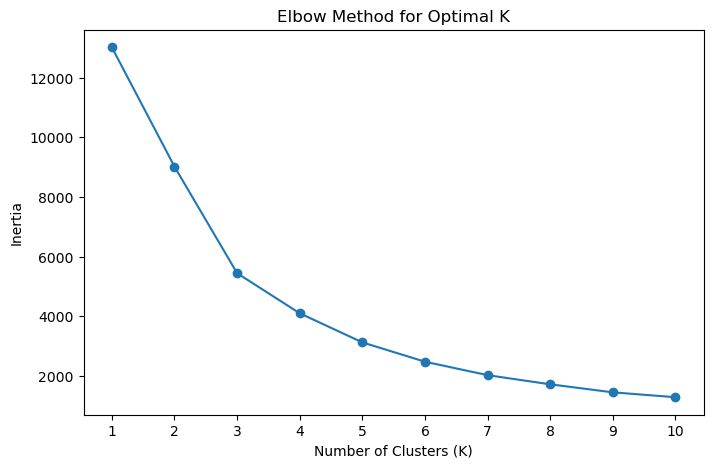

In [24]:
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, 11),
    inertia,
    marker='o'
)
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.show()

### Choosing the Number of Clusters

The Elbow Method helps identify a suitable cluster count by examining where the inertia curve begins to flatten.

Based on the observed elbow in the plot, four clusters are selected for customer segmentation.

This provides a practical balance between cluster separation and ease of business interpretation.

## 7. Customer Segmentation Using K-Means

K-Means clustering is applied to group customers based on their scaled RFM characteristics.

Four clusters are created based on the Elbow Method analysis.

Each customer is assigned a cluster representing a group of customers with similar purchasing behaviour.

In [25]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Display customer clusters
rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,325,1,77183.60,0
12347.0,1,7,4310.00,3
12348.0,74,4,1797.24,3
12349.0,18,1,1757.55,3
12350.0,309,1,334.40,1


In [41]:
from sklearn.metrics import silhouette_score
score = silhouette_score(rfm_scaled, rfm['Cluster'])
print("Silhouette Score:", score)

Silhouette Score: 0.6161304312712135


# Silhouette Score Evaluation
The Silhouette Score was used to evaluate the quality of the K-Means clustering model. The model achieved a score of 0.616, indicating good cluster separation and reasonably well-defined customer groups.
This suggests that the four customer segments identified by the model have a meaningful level of separation.

In [26]:
cluster_summary = rfm.groupby('Cluster')[
    ['Recency', 'Frequency', 'Monetary']
].mean()

cluster_summary

,Recency,Frequency,Monetary
Cluster,,,
0,14.672986,22.047393,12435.086682
1,247.564030,1.551789,476.330547
2,6.384615,82.692308,127187.959231
3,42.910580,3.655748,1344.284013


### Cluster Interpretation

The average Recency, Frequency, and Monetary values are used to understand the purchasing behaviour of each cluster.

- Lower Recency indicates more recent purchases.
- Higher Frequency indicates more frequent purchases.
- Higher Monetary indicates greater customer spending.

The cluster averages are examined before assigning business-oriented customer segment labels.

### Final Customer Segmentation

The cluster labels are interpreted using their average RFM values. Cluster numbers are generated by the algorithm and do not have an inherent business meaning.

In [27]:
# Assign business-oriented customer segment labels
rfm['Segment'] = rfm['Cluster'].map({
    2: 'VIP Customers',
    0: 'Loyal Customers',
    1: 'At Risk Customers',
    3: 'Low Value Customers'
})

# Preview final customer segmentation
rfm.head()

,Recency,Frequency,Monetary,Cluster,Segment
CustomerID,,,,,
12346.0,325,1,77183.60,0,Loyal Customers
12347.0,1,7,4310.00,3,Low Value Customers
12348.0,74,4,1797.24,3,Low Value Customers
12349.0,18,1,1757.55,3,Low Value Customers
12350.0,309,1,334.40,1,At Risk Customers


In [28]:
segment_counts = rfm['Segment'].value_counts()

segment_counts

Segment
Low Value Customers    3053
At Risk Customers      1062
Loyal Customers         211
VIP Customers            13
Name: count, dtype: int64

In [29]:
segment_summary = rfm.groupby('Segment')[
    ['Recency', 'Frequency', 'Monetary']
].mean().round(2)

segment_summary

,Recency,Frequency,Monetary
Segment,,,
At Risk Customers,247.56,1.55,476.33
Low Value Customers,42.91,3.66,1344.28
Loyal Customers,14.67,22.05,12435.09
VIP Customers,6.38,82.69,127187.96


### Customer Segment Interpretation

Based on the cluster averages:

- **VIP Customers:** Customers with very recent purchases, the highest purchase frequency, and the highest monetary value.
- **Loyal Customers:** Customers who purchase frequently and contribute significant revenue.
- **At Risk Customers:** Customers with high recency, indicating that they have not purchased for a long time, along with relatively low frequency and spending.
- **Low Value Customers:** Customers with lower purchase frequency and monetary contribution.

### Business Implications

- Reward VIP customers through loyalty programmes and exclusive offers.
- Maintain engagement with loyal customers to encourage repeat purchases.
- Target at-risk customers through personalised re-engagement campaigns.
- Encourage low-value customers to increase purchase frequency and spending.

## 8. Exporting Data for Power BI

The final customer segmentation, cleaned purchase dataset, and return dataset are exported as CSV files.

These files can be imported into Power BI to build interactive dashboards for sales performance, customer segmentation, and returns analysis.

In [30]:
rfm.to_csv(
    "rfm_data.csv",
    index=True,
    index_label="CustomerID"
)

print("rfm_data.csv exported successfully.")

rfm_data.csv exported successfully.


In [31]:
c_data.to_csv("cleaned_data.csv", index=False)

print("cleaned_data.csv exported successfully.")

cleaned_data.csv exported successfully.


## 9. Returns Analysis

Negative quantities in the original dataset represent product returns or cancellations.

A separate returns dataset was created during data cleaning to analyse these transactions independently from customer purchases.

This section examines:

- Total number of return records.
- Number of distinct return invoices.
- Total return value.
- Most frequently returned products.
- Countries with the highest number of return records.

In [32]:
returns_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [33]:
returns_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8872 entries, 141 to 541717
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    8872 non-null   object        
 1   StockCode    8872 non-null   object        
 2   Description  8872 non-null   object        
 3   Quantity     8872 non-null   int64         
 4   InvoiceDate  8872 non-null   datetime64[ns]
 5   UnitPrice    8872 non-null   float64       
 6   CustomerID   8872 non-null   float64       
 7   Country      8872 non-null   object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 623.8+ KB


In [34]:
returns_df['TotalPrice'] = (
    returns_df['Quantity'] * returns_df['UnitPrice']
)

returns_df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,-27.50
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,-4.65
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,-19.80
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96


In [35]:
total_return_records = len(returns_df)
print("Total Return Records:", total_return_records)

Total Return Records: 8872


In [36]:
total_return_invoices = returns_df['InvoiceNo'].nunique()
print("Distinct Return Invoices:", total_return_invoices)

Distinct Return Invoices: 3654


In [37]:
total_return_value = returns_df['TotalPrice'].sum()
print("Total Return Value: £{:,.2f}".format(total_return_value))

Total Return Value: £-608,689.47


### Top Returned Products

Identifying frequently returned products helps businesses understand which products may require further investigation.

The following analysis identifies the top ten products based on the number of return records.

In [38]:
top_returned_products = (
    returns_df['Description']
    .value_counts()
    .head(10)
)
top_returned_products

Description
REGENCY CAKESTAND 3 TIER             180
Manual                               175
POSTAGE                               97
JAM MAKING SET WITH JARS              86
Discount                              77
SET OF 3 CAKE TINS PANTRY DESIGN      72
STRAWBERRY CERAMIC TRINKET BOX        54
ROSES REGENCY TEACUP AND SAUCER       53
RECIPE BOX PANTRY YELLOW DESIGN       47
JUMBO BAG RED RETROSPOT               44
Name: count, dtype: int64

In [39]:
returns_by_country = (
    returns_df['Country']
    .value_counts()
    .head(10)
)
returns_by_country

Country
United Kingdom    7501
Germany            453
EIRE               247
France             148
USA                112
Australia           74
Spain               48
Italy               45
Belgium             38
Japan               37
Name: count, dtype: int64

In [40]:
returns_df.to_csv("returns_data.csv", index=False)
print("returns_data.csv exported successfully.")

returns_data.csv exported successfully.


## 10. Final Business Insights and Recommendations

### Customer Segmentation

- RFM analysis and K-Means clustering identified four distinct customer segments.
- VIP customers demonstrate the highest purchase frequency and monetary contribution.
- Loyal customers contribute significant revenue through repeat purchases.
- At-risk customers may require targeted re-engagement campaigns.
- Low-value customers represent an opportunity to improve purchase frequency and spending.

### Sales Analysis

- Total purchase revenue is approximately £8.89 million.
- Customer-level RFM analysis was performed for 4,339 customers.

### Returns Analysis

- A total of 8,872 return records were identified.
- These records correspond to 3,654 distinct return invoices.
- The total return value is approximately -£608,689.47.
- The United Kingdom accounts for the highest number of return records.
- REGENCY CAKESTAND 3 TIER is the most frequently returned product in the analysis.

### Business Recommendations

1. Develop loyalty programmes and personalised offers for VIP customers.
2. Focus on customer retention through targeted campaigns for at-risk customers.
3. Encourage repeat purchases among low-value customers.
4. Investigate frequently returned products to identify possible quality or product-description issues.
5. Monitor country-level return patterns to identify opportunities to improve customer experience and operations.

### Power BI Dashboard

The exported datasets are used to create an interactive Power BI report with three analytical pages:

- Sales Overview
- Customer Analysis & Segmentation
- Return Analysis

The dashboard enables business users to explore sales performance, customer behaviour, and product return patterns.